## Conexión con google drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/BigData_FE', exist_ok=True)
print("Drive conectado. Carpeta BigData_FE lista.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive conectado. Carpeta BigData_FE lista.


## FASE 1. Instalación
**Qué se instala:** Java (lo necesitan Hadoop y Spark), Spark (con `pyspark`) y Hadoop (HDFS + MapReduce).
Se fija `pyspark==3.5.1` porque es compatible con el Java 11 que se instala aquí.

In [8]:
# 1.1 Java y Spark
!pip install -q pyspark==3.5.1 2> /dev/null
!pip install -q pyspark==3.5.1
print("Java y Spark instalados")

Java y Spark instalados


In [4]:
# 1.2 Hadoop 3.3.6
!wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz
!tar -xzf hadoop-3.3.6.tar.gz
!ls /content/hadoop-3.3.6

bin  include  libexec	      licenses-binary  NOTICE-binary  README.txt  share
etc  lib      LICENSE-binary  LICENSE.txt      NOTICE.txt     sbin


In [5]:
# 1.3 Variables de entorno (le dicen al sistema dónde están Java y Hadoop)
import os
JAVA = "/usr/lib/jvm/java-11-openjdk-amd64"
HADOOP = "/content/hadoop-3.3.6"
os.environ["JAVA_HOME"] = JAVA
os.environ["HADOOP_HOME"] = HADOOP
os.environ["PATH"] = f"{JAVA}/bin:{HADOOP}/bin:{HADOOP}/sbin:" + os.environ["PATH"]
# Hadoop exige indicar con qué usuario corren sus servicios (en Colab es "root")
for v in ["HDFS_NAMENODE_USER", "HDFS_DATANODE_USER", "HDFS_SECONDARYNAMENODE_USER",
          "YARN_RESOURCEMANAGER_USER", "YARN_NODEMANAGER_USER"]:
    os.environ[v] = "root"
print("Variables de entorno listas")

Variables de entorno listas


## FASE 2. Verificación de la instalación

In [6]:
# 2.1 Versiones instaladas
!java -version
!hadoop version
import pyspark
print("PySpark:", pyspark.__version__)

openjdk version "11.0.32.1" 2026-08-18
OpenJDK Runtime Environment (build 11.0.32.1+1-post-1ubuntu1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 11.0.32.1+1-post-1ubuntu1-24.04-Ubuntu, mixed mode, sharing)
Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /content/hadoop-3.3.6/share/hadoop/common/hadoop-common-3.3.6.jar
PySpark: 3.5.1


In [7]:
# 2.2 Encender Spark
from pyspark.sql import SparkSession
spark = (SparkSession.builder.master("local[*]").appName("FacturacionElectronica")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
sc = spark.sparkContext
print("Spark activo. Versión:", spark.version, "| núcleos disponibles:", sc.defaultParallelism)

Spark activo. Versión: 3.5.1 | núcleos disponibles: 2


**2.3 Prueba rápida de MapReduce** con el programa de ejemplo que trae Hadoop (WordCount). Aquí todavía trabaja sobre archivos locales; más adelante se usará HDFS.

In [9]:
%%writefile /content/datos_prueba.txt
factura electronica dian
factura electronica restaurante
dian resolucion factura
restaurante chapinero factura

Writing /content/datos_prueba.txt


In [10]:
!mkdir -p /content/prueba_entrada && cp /content/datos_prueba.txt /content/prueba_entrada/
!rm -rf /content/prueba_salida
!hadoop jar /content/hadoop-3.3.6/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.3.6.jar wordcount file:///content/prueba_entrada file:///content/prueba_salida 2>&1 | tail -n 12
!cat /content/prueba_salida/part-r-00000

		Total committed heap usage (bytes)=782237696
	Shuffle Errors
		BAD_ID=0
		CONNECTION=0
		IO_ERROR=0
		WRONG_LENGTH=0
		WRONG_MAP=0
		WRONG_REDUCE=0
	File Input Format Counters 
		Bytes Read=111
	File Output Format Counters 
		Bytes Written=82
chapinero	1
dian	2
electronica	2
factura	4
resolucion	1
restaurante	2


## FASE 3. Configurar y encender HDFS
**HDFS** es el sistema de archivos de Hadoop: guarda los archivos grandes **partidos en bloques**, repartidos y replicados entre varios computadores. Aquí se simula un clúster de un solo nodo (modo *pseudo-distribuido*).

Hay dos servicios:
- **NameNode:** el "índice": sabe qué bloques tiene cada archivo y dónde están.
- **DataNode:** guarda los bloques de datos.

Primero se editan los archivos de configuración:

- `core-site.xml`: dirección del sistema de archivos (`fs.defaultFS`).
- `hdfs-site.xml`: réplicas (`dfs.replication`) y carpetas donde se guardan los metadatos y los bloques.

In [11]:
%%writefile /content/hadoop-3.3.6/etc/hadoop/core-site.xml
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:9000</value>
  </property>
</configuration>

Overwriting /content/hadoop-3.3.6/etc/hadoop/core-site.xml


In [12]:
%%writefile /content/hadoop-3.3.6/etc/hadoop/hdfs-site.xml
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>dfs.replication</name>
    <value>1</value>
  </property>
  <property>
    <name>dfs.namenode.name.dir</name>
    <value>file:///content/hdfs/namenode</value>
  </property>
  <property>
    <name>dfs.datanode.data.dir</name>
    <value>file:///content/hdfs/datanode</value>
  </property>
</configuration>

Overwriting /content/hadoop-3.3.6/etc/hadoop/hdfs-site.xml


In [13]:
# 3.3 Indicar Java en la configuración de Hadoop y mostrar los archivos editados
!echo "export JAVA_HOME=/usr/lib/jvm/java-11-openjdk-amd64" >> /content/hadoop-3.3.6/etc/hadoop/hadoop-env.sh
!tail -n 2 /content/hadoop-3.3.6/etc/hadoop/hadoop-env.sh
!cat /content/hadoop-3.3.6/etc/hadoop/core-site.xml
!cat /content/hadoop-3.3.6/etc/hadoop/hdfs-site.xml

# export HADOOP_REGISTRYDNS_SECURE_EXTRA_OPTS="-jvm server"
export JAVA_HOME=/usr/lib/jvm/java-11-openjdk-amd64
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:9000</value>
  </property>
</configuration>
<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>dfs.replication</name>
    <value>1</value>
  </property>
  <property>
    <name>dfs.namenode.name.dir</name>
    <value>file:///content/hdfs/namenode</value>
  </property>
  <property>
    <name>dfs.datanode.data.dir</name>
    <value>file:///content/hdfs/datanode</value>
  </property>
</configuration>


In [14]:
# 3.4 Formatear el NameNode
!hdfs namenode -format -force -nonInteractive 2>&1 | tail -n 8

2026-11-07 16:07:16,439 INFO namenode.NNStorageRetentionManager: Going to retain 1 images with txid >= 0
2026-11-07 16:07:16,506 INFO namenode.FSNamesystem: Stopping services started for active state
2026-11-07 16:07:16,506 INFO namenode.FSNamesystem: Stopping services started for standby state
2026-11-07 16:07:16,512 INFO namenode.FSImage: FSImageSaver clean checkpoint: txid=0 when meet shutdown.
2026-11-07 16:07:16,513 INFO namenode.NameNode: SHUTDOWN_MSG: 
/************************************************************
SHUTDOWN_MSG: Shutting down NameNode at 056827cf4ce6/172.28.0.12
************************************************************/


In [15]:
# 3.5 Encender los servicios de HDFS
!hdfs --daemon start namenode
!hdfs --daemon start datanode
print("Servicios lanzados. Esperando a que HDFS responda...")

Servicios lanzados. Esperando a que HDFS responda...


In [16]:
# 3.6 Esperar y comprobar que HDFS está activo
import time, subprocess
for i in range(40):
    r = subprocess.run(["hdfs", "dfs", "-ls", "/"], capture_output=True, text=True)
    if r.returncode == 0:
        print("HDFS responde correctamente")
        break
    time.sleep(3)
else:
    print("HDFS no respondió. Revisa los registros con: !tail -n 30 /content/hadoop-3.3.6/logs/*namenode*.log")
!hdfs dfsadmin -safemode wait
!jps

HDFS responde correctamente
Safe mode is OFF
13188 NameNode
11707 SparkSubmit
13612 Jps
13247 DataNode


In [17]:
# 3.7 Informe de estado del HDFS (capacidad, DataNodes activos)
!hdfs dfsadmin -report | head -n 25

Configured Capacity: 115658190848 (107.72 GB)
Present Capacity: 112110669824 (104.41 GB)
DFS Remaining: 112110645248 (104.41 GB)
DFS Used: 24576 (24 KB)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-------------------------------------------------
Live datanodes (1):

Name: 127.0.0.1:9866 (localhost)
Hostname: 056827cf4ce6
Decommission Status : Normal


## FASE 4. Datos: generación y revisión
Se generan **200.000 facturas simuladas** con patrones inventados, para que haya algo que interpretar:
- Más facturación en **junio-julio y diciembre**; menos en febrero.
- El **ticket promedio** es mayor en Bogotá-Chapinero y menor en Zipaquirá; los fines de semana son más altos.
- La **tasa de rechazo ante la DIAN** es mayor en Chía, y las notas crédito/débito se rechazan más que las facturas.
- Los **motivos de rechazo** cambian por ciudad (por ejemplo, numeración vencida pesa más en Chía).
- Los **medios de pago** cambian por ciudad (más efectivo en Zipaquirá, más tarjeta en Chapinero).

Columnas: `id_factura, fecha, ciudad, tipo_documento, valor, medio_pago, estado_dian, motivo_rechazo`

In [18]:
import csv, random, os, calendar
from datetime import date

random.seed(42)
N = 200000
os.makedirs("/content/datos", exist_ok=True)

ciudades = ["Bogotá-Chapinero", "Chía", "Cajicá", "Zipaquirá"]
peso_ciudad = [40, 30, 15, 15]
tipos = ["Factura electrónica", "Nota crédito", "Nota débito", "Documento soporte"]
peso_tipo = [70, 15, 5, 10]
pagos = ["Efectivo", "Tarjeta", "Transferencia", "Nequi/Daviplata"]
peso_pago = {"Bogotá-Chapinero": [15, 45, 20, 20], "Chía": [25, 35, 20, 20],
             "Cajicá": [30, 30, 20, 20], "Zipaquirá": [45, 20, 15, 20]}
motivos = ["NIT del adquiriente inválido", "Resolución de numeración vencida",
           "Error en firma o XML", "Fecha fuera de rango", "Totales no coinciden"]
peso_motivo = {"Bogotá-Chapinero": [20, 10, 40, 10, 20], "Chía": [15, 45, 20, 10, 10],
               "Cajicá": [25, 25, 20, 15, 15], "Zipaquirá": [30, 30, 15, 10, 15]}
prob_rechazo = {"Bogotá-Chapinero": 0.06, "Chía": 0.17, "Cajicá": 0.10, "Zipaquirá": 0.12}
mult_tipo = {"Factura electrónica": 1.0, "Nota crédito": 1.8, "Nota débito": 1.4, "Documento soporte": 0.8}
ticket_base = {"Bogotá-Chapinero": 95000, "Chía": 70000, "Cajicá": 62000, "Zipaquirá": 48000}
peso_mes = [8, 6, 8, 8, 9, 10, 10, 8, 8, 9, 10, 14]   # enero ... diciembre

filas = []
for _ in range(N):
    mes = random.choices(range(1, 13), weights=peso_mes)[0]
    dia = random.randint(1, calendar.monthrange(2025, mes)[1])
    f = date(2025, mes, dia)
    ciudad = random.choices(ciudades, weights=peso_ciudad)[0]
    tipo = random.choices(tipos, weights=peso_tipo)[0]
    valor = ticket_base[ciudad] * mult_tipo[tipo] * random.lognormvariate(0, 0.45)
    if f.weekday() >= 5:
        valor *= 1.25
    valor = int(min(max(round(valor, -2), 8000), 2000000))
    pago = random.choices(pagos, weights=peso_pago[ciudad])[0]
    p = prob_rechazo[ciudad] * (1.0 if tipo == "Factura electrónica" else 1.5)
    r = random.random()
    if r < p:
        estado = "Rechazada"
        motivo = random.choices(motivos, weights=peso_motivo[ciudad])[0]
    elif r < p + 0.05:
        estado, motivo = "Pendiente", ""
    else:
        estado, motivo = "Aceptada", ""
    filas.append((f.isoformat(), ciudad, tipo, valor, pago, estado, motivo))

filas.sort(key=lambda x: x[0])   # ordenadas por fecha, como en un sistema real
with open("/content/datos/facturas.csv", "w", newline="", encoding="utf-8") as archivo:
    w = csv.writer(archivo, lineterminator="\n")
    w.writerow(["id_factura", "fecha", "ciudad", "tipo_documento", "valor", "medio_pago", "estado_dian", "motivo_rechazo"])
    for i, fila in enumerate(filas, start=1):
        w.writerow([i, *fila])
print("Archivo creado: /content/datos/facturas.csv")

Archivo creado: /content/datos/facturas.csv


In [19]:
# 4.2 Verificar el archivo
!head -6 /content/datos/facturas.csv
!wc -l /content/datos/facturas.csv
!du -h /content/datos/facturas.csv

id_factura,fecha,ciudad,tipo_documento,valor,medio_pago,estado_dian,motivo_rechazo
1,2025-01-01,Chía,Factura electrónica,54400,Tarjeta,Aceptada,
2,2025-01-01,Chía,Factura electrónica,65300,Tarjeta,Aceptada,
3,2025-01-01,Chía,Factura electrónica,58900,Tarjeta,Aceptada,
4,2025-01-01,Chía,Nota crédito,152800,Nequi/Daviplata,Rechazada,Fecha fuera de rango
5,2025-01-01,Bogotá-Chapinero,Factura electrónica,151500,Efectivo,Aceptada,
200001 /content/datos/facturas.csv
16M	/content/datos/facturas.csv


In [20]:
# 4.3 Perfil rápido de los datos (estructura, tipos y estadísticas)
import pandas as pd
pdf = pd.read_csv("/content/datos/facturas.csv")
pdf.info()
display(pdf.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id_factura      200000 non-null  int64 
 1   fecha           200000 non-null  object
 2   ciudad          200000 non-null  object
 3   tipo_documento  200000 non-null  object
 4   valor           200000 non-null  int64 
 5   medio_pago      200000 non-null  object
 6   estado_dian     200000 non-null  object
 7   motivo_rechazo  24943 non-null   object
dtypes: int64(2), object(6)
memory usage: 12.2+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_factura,200000.0,NaN,NaN,NaN,100000.5,57735.171256,1.0,50000.75,100000.5,150000.25,200000.0
fecha,200000,365,2025-12-01,889,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ciudad,200000,4,Bogotá-Chapinero,80140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_documento,200000,4,Factura electrónica,139850,NaN,NaN,NaN,NaN,NaN,NaN,NaN
valor,200000.0,NaN,NaN,NaN,100263.921,63420.01546,8000.0,57600.0,84400.0,124400.0,868100.0
medio_pago,200000,4,Tarjeta,71849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_dian,200000,3,Aceptada,165169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
motivo_rechazo,24943,5,Resolución de numeración vencida,7854,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# 4.4 Visualización de las 10 primeras filas de la base de datos
import pandas as pd
pdf = pd.read_csv("/content/datos/facturas.csv")
pdf.head(10)

,id_factura,fecha,ciudad,tipo_documento,valor,medio_pago,estado_dian,motivo_rechazo
0,1,2025-01-01,Chía,Factura electrónica,54400,Tarjeta,Aceptada,NaN
1,2,2025-01-01,Chía,Factura electrónica,65300,Tarjeta,Aceptada,NaN
2,3,2025-01-01,Chía,Factura electrónica,58900,Tarjeta,Aceptada,NaN
3,4,2025-01-01,Chía,Nota crédito,152800,Nequi/Daviplata,Rechazada,Fecha fuera de rango
4,5,2025-01-01,Bogotá-Chapinero,Factura electrónica,151500,Efectivo,Aceptada,NaN
5,6,2025-01-01,Chía,Factura electrónica,75200,Tarjeta,Aceptada,NaN
6,7,2025-01-01,Zipaquirá,Factura electrónica,86200,Nequi/Daviplata,Aceptada,NaN
7,8,2025-01-01,Zipaquirá,Nota crédito,142800,Tarjeta,Rechazada,Fecha fuera de rango
8,9,2025-01-01,Cajicá,Nota crédito,66100,Transferencia,Aceptada,NaN
9,10,2025-01-01,Chía,Factura electrónica,48500,Tarjeta,Aceptada,NaN


In [22]:
# 4.4 Copia de respaldo en Drive (para no tener que regenerar los datos si se cierra la sesión)
!cp /content/datos/facturas.csv /content/drive/MyDrive/BigData_FE/facturas.csv
!ls -lh /content/drive/MyDrive/BigData_FE/

total 16M
-rw------- 1 root root 16M Nov  7 16:12 facturas.csv


## FASE 5. Comandos básicos de HDFS
Los comandos de HDFS empiezan con `hdfs dfs` y se parecen a los de Linux (`-ls`, `-mkdir`, `-cat`, `-rm`...).
Se sube el archivo con **bloques de 4 MB** (en vez de los 128 MB por defecto) para que el archivo de ~16 MB quede partido en varios bloques y se vea cómo HDFS reparte los datos. Más adelante, cada bloque será procesado por una tarea *Map* distinta.

In [23]:
%%bash
# 5.1 Crear carpetas en HDFS
hdfs dfs -mkdir -p /user/root/entrada
hdfs dfs -mkdir -p /user/root/texto
hdfs dfs -ls /user
hdfs dfs -ls /user/root

Found 1 items
drwxr-xr-x   - root supergroup          0 2026-11-07 16:13 /user/root
Found 2 items
drwxr-xr-x   - root supergroup          0 2026-11-07 16:13 /user/root/entrada
drwxr-xr-x   - root supergroup          0 2026-11-07 16:13 /user/root/texto


In [24]:
%%bash
# 5.2 Subir el archivo a HDFS (bloques de 4 MB)
hdfs dfs -D dfs.blocksize=4194304 -put -f /content/datos/facturas.csv /user/root/entrada/facturas.csv
hdfs dfs -ls -h /user/root/entrada

Found 1 items
-rw-r--r--   1 root supergroup     15.1 M 2026-11-07 16:13 /user/root/entrada/facturas.csv


In [25]:
%%bash
# 5.3 Inspeccionar el archivo dentro de HDFS
echo "== Espacio usado =="
hdfs dfs -du -h /user/root/entrada
echo "== Carpetas / archivos / bytes =="
hdfs dfs -count -h /user/root
echo "== Primeras líneas =="
hdfs dfs -cat /user/root/entrada/facturas.csv 2>/dev/null | head -5
echo "== Últimas líneas =="
hdfs dfs -tail /user/root/entrada/facturas.csv 2>/dev/null | tail -3
echo "== Metadatos (tamaño, bloque, réplicas) =="
hdfs dfs -stat "%n | tamaño=%b bytes | tamaño de bloque=%o | réplicas=%r" /user/root/entrada/facturas.csv

== Espacio usado ==
15.1 M  15.1 M  /user/root/entrada/facturas.csv
== Carpetas / archivos / bytes ==
           3            1             15.1 M /user/root
== Primeras líneas ==
id_factura,fecha,ciudad,tipo_documento,valor,medio_pago,estado_dian,motivo_rechazo
1,2025-01-01,Chía,Factura electrónica,54400,Tarjeta,Aceptada,
2,2025-01-01,Chía,Factura electrónica,65300,Tarjeta,Aceptada,
3,2025-01-01,Chía,Factura electrónica,58900,Tarjeta,Aceptada,
4,2025-01-01,Chía,Nota crédito,152800,Nequi/Daviplata,Rechazada,Fecha fuera de rango
== Últimas líneas ==
199998,2025-12-31,Chía,Factura electrónica,143100,Nequi/Daviplata,Aceptada,
199999,2025-12-31,Chía,Factura electrónica,50000,Tarjeta,Aceptada,
200000,2025-12-31,Bogotá-Chapinero,Factura electrónica,103400,Tarjeta,Aceptada,
== Metadatos (tamaño, bloque, réplicas) ==
facturas.csv | tamaño=15875698 bytes | tamaño de bloque=4194304 | réplicas=1


In [26]:
%%bash
# 5.4 Ver cómo quedó partido el archivo en bloques (fsck)
hdfs fsck /user/root/entrada/facturas.csv -files -blocks -locations 2>&1 | head -n 25

Connecting to namenode via http://localhost:9870/fsck?ugi=root&files=1&blocks=1&locations=1&path=%2Fuser%2Froot%2Fentrada%2Ffacturas.csv
FSCK started by root (auth:SIMPLE) from /127.0.0.1 for path /user/root/entrada/facturas.csv at Sat Nov 07 16:14:03 UTC 2026

/user/root/entrada/facturas.csv 15875698 bytes, replicated: replication=1, 4 block(s):  OK
0. BP-36338871-172.28.0.12-1794067635934:blk_1073741825_1001 len=4194304 Live_repl=1  [DatanodeInfoWithStorage[127.0.0.1:9866,DS-2c82db1f-e2e9-4729-ba43-70292b902464,DISK]]
1. BP-36338871-172.28.0.12-1794067635934:blk_1073741826_1002 len=4194304 Live_repl=1  [DatanodeInfoWithStorage[127.0.0.1:9866,DS-2c82db1f-e2e9-4729-ba43-70292b902464,DISK]]
2. BP-36338871-172.28.0.12-1794067635934:blk_1073741827_1003 len=4194304 Live_repl=1  [DatanodeInfoWithStorage[127.0.0.1:9866,DS-2c82db1f-e2e9-4729-ba43-70292b902464,DISK]]
3. BP-36338871-172.28.0.12-1794067635934:blk_1073741828_1004 len=3292786 Live_repl=1  [DatanodeInfoWithStorage[127.0.0.1:9866,DS

In [27]:
%%bash
# 5.5 Copiar, renombrar y borrar archivos
hdfs dfs -cp /user/root/entrada/facturas.csv /user/root/entrada/copia.csv
hdfs dfs -mv /user/root/entrada/copia.csv /user/root/entrada/copia_renombrada.csv
hdfs dfs -ls /user/root/entrada
hdfs dfs -rm /user/root/entrada/copia_renombrada.csv
hdfs dfs -ls /user/root/entrada

Found 2 items
-rw-r--r--   1 root supergroup   15875698 2026-11-07 16:14 /user/root/entrada/copia_renombrada.csv
-rw-r--r--   1 root supergroup   15875698 2026-11-07 16:13 /user/root/entrada/facturas.csv
Deleted /user/root/entrada/copia_renombrada.csv
Found 1 items
-rw-r--r--   1 root supergroup   15875698 2026-11-07 16:13 /user/root/entrada/facturas.csv


In [28]:
%%bash
# 5.6 Ajustar el factor de replicación (cuántas copias de cada bloque)
hdfs dfs -setrep -w 1 /user/root/entrada/facturas.csv
hdfs dfs -stat "réplicas=%r" /user/root/entrada/facturas.csv

Replication 1 set: /user/root/entrada/facturas.csv
Waiting for /user/root/entrada/facturas.csv ... done
réplicas=1


## FASE 6. MapReduce con scripts en Python (Hadoop Streaming)
**Idea central:** MapReduce procesa los datos en tres momentos.
1. **Map:** cada línea del archivo se convierte en un par `clave → valor` (por ejemplo `Chía → 1`).
2. **Shuffle/Sort:** Hadoop reúne todos los pares con la misma clave.
3. **Reduce:** se combinan los valores de cada clave (sumar, contar, promediar...).

*Hadoop Streaming* permite escribir el mapper y el reducer en Python en lugar de Java.

Columnas del archivo (empezando en 0): `0 id_factura, 1 fecha, 2 ciudad, 3 tipo_documento, 4 valor, 5 medio_pago, 6 estado_dian, 7 motivo_rechazo`

**6.1 a 6.4: scripts.** Un mapper genérico (se le dice por cuál columna agrupar y cuál sumar) y dos reducers.

In [29]:
%%writefile /content/mapper.py
#!/usr/bin/env python3
import sys
# Uso: mapper.py columnas_clave [columna_valor]
#   columnas_clave: una o varias columnas separadas por coma (ej. "2" o "2,6")
#   columna_valor : columna numérica a sumar; si se omite, cada fila vale 1 (conteo)
claves = [int(c) for c in sys.argv[1].split(",")]
col_valor = int(sys.argv[2]) if len(sys.argv) > 2 else None
for linea in sys.stdin:
    p = linea.rstrip("\r\n").split(",")
    if len(p) < 8 or p[0] == "id_factura":      # salta el encabezado y filas incompletas
        continue
    clave = "|".join(p[c] for c in claves)
    valor = p[col_valor] if col_valor is not None else "1"
    print(f"{clave}\t{valor}")

Writing /content/mapper.py


In [30]:
%%writefile /content/reducer_suma.py
#!/usr/bin/env python3
import sys
# Suma los valores de cada clave. Sirve para contar (valores = 1) y para totalizar montos.
actual, total = None, 0
for linea in sys.stdin:
    clave, valor = linea.rstrip("\r\n").split("\t")
    if clave == actual:
        total += int(valor)
    else:
        if actual is not None:
            print(f"{actual}\t{total}")
        actual, total = clave, int(valor)
if actual is not None:
    print(f"{actual}\t{total}")

Writing /content/reducer_suma.py


In [31]:
%%writefile /content/reducer_promedio.py
#!/usr/bin/env python3
import sys
# Calcula el promedio de los valores de cada clave.
actual, suma, n = None, 0, 0
for linea in sys.stdin:
    clave, valor = linea.rstrip("\r\n").split("\t")
    if clave == actual:
        suma += int(valor)
        n += 1
    else:
        if actual is not None:
            print(f"{actual}\t{suma / n:.2f}")
        actual, suma, n = clave, int(valor), 1
if actual is not None:
    print(f"{actual}\t{suma / n:.2f}")

Writing /content/reducer_promedio.py


In [32]:
%%writefile /content/mapper_mes.py
#!/usr/bin/env python3
import sys
# Emite (año-mes, valor) para totalizar ventas por mes.
for linea in sys.stdin:
    p = linea.rstrip("\r\n").split(",")
    if len(p) < 8 or p[0] == "id_factura":
        continue
    print(f"{p[1][:7]}\t{p[4]}")

Writing /content/mapper_mes.py


In [33]:
%%writefile /content/mapper_rechazo.py
#!/usr/bin/env python3
import sys
# Solo procesa los documentos rechazados y emite (ciudad|motivo, 1).
for linea in sys.stdin:
    p = linea.rstrip("\r\n").split(",")
    if len(p) < 8 or p[0] == "id_factura":
        continue
    if p[6] == "Rechazada":
        print(f"{p[2]}|{p[7]}\t1")

Writing /content/mapper_rechazo.py


**6.5 Prueba local de los scripts, sin Hadoop.** Simula el flujo Map → Shuffle/Sort (`sort`) → Reduce sobre las primeras 2.000 filas. Sirve para depurar antes de lanzar el trabajo real.

In [36]:
!echo "== Salida del MAPPER (primeras 5 líneas) =="
!head -2000 /content/datos/facturas.csv | python3 /content/mapper.py 2 2>/dev/null | head -5
!echo "== Resultado tras SORT + REDUCER =="
!head -2000 /content/datos/facturas.csv | python3 /content/mapper.py 2 | sort | python3 /content/reducer_suma.py

== Salida del MAPPER (primeras 5 líneas) ==
Chía	1
Chía	1
Chía	1
Chía	1
Bogotá-Chapinero	1
== Resultado tras SORT + REDUCER ==
Bogotá-Chapinero	763
Cajicá	333
Chía	610
Zipaquirá	293


**6.6 Funciones de ayuda.** `mr(...)` lanza un trabajo MapReduce sobre HDFS, **muestra el comando que ejecuta** y los *contadores* clave del trabajo. `ver(...)` lee el resultado desde HDFS como tabla.

In [37]:
import subprocess, re, time, io
import pandas as pd

STREAMING = "/content/hadoop-3.3.6/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar"
ENTRADA = "/user/root/entrada/facturas.csv"
CONTADORES = ["Launched map tasks", "Launched reduce tasks", "Map input records", "Map output records",
              "Combine input records", "Combine output records", "Reduce input records", "Reduce output records"]

def mr(salida, mapper, reducer, combiner=None, reducers=1, entrada=ENTRADA):
    """Ejecuta un trabajo MapReduce (Hadoop Streaming) sobre HDFS y muestra comando, contadores y tiempo."""
    subprocess.run(["hdfs", "dfs", "-rm", "-r", "-f", f"/user/root/{salida}"], capture_output=True)
    cmd = ["hadoop", "jar", STREAMING, "-D", f"mapreduce.job.reduces={reducers}",
           "-input", entrada, "-output", f"/user/root/{salida}",
           "-mapper", mapper, "-reducer", reducer]
    if combiner:
        cmd += ["-combiner", combiner]
    print("COMANDO: hadoop jar hadoop-streaming-3.3.6.jar", " ".join(cmd[3:]))
    t0 = time.time()
    r = subprocess.run(cmd, capture_output=True, text=True)
    seg = time.time() - t0
    if r.returncode != 0:
        print(r.stderr[-3000:])
        raise RuntimeError("El trabajo falló; copia el mensaje de arriba y consúltalo.")
    cont = {}
    for nombre in CONTADORES:
        m = re.search(rf"^\s*{re.escape(nombre)}=(\d+)", r.stderr, re.M)
        if m:
            cont[nombre] = int(m.group(1))
    print(f"Tiempo total: {seg:.1f} s")
    for k, v in cont.items():
        print(f"  {k}: {v:,}")
    return cont, seg

def ver(salida, ordenar=True, ascendente=False):
    """Lee la salida de un trabajo desde HDFS y la devuelve como tabla (clave, valor)."""
    txt = subprocess.run(["hdfs", "dfs", "-cat", f"/user/root/{salida}/part-*"],
                         capture_output=True, text=True).stdout.replace("\r", "")
    df = pd.read_csv(io.StringIO(txt), sep="\t", header=None, names=["clave", "valor"], quoting=3)
    if ordenar:
        df = df.sort_values("valor", ascending=ascendente)
    return df.reset_index(drop=True)

print("Funciones listas")

Funciones listas


### Ejercicio MR-1. Cantidad de facturas por ciudad
Se escribe el comando completo para que quede como evidencia. En el registro final busca los **contadores** (*Map input records*, *Launched map tasks*, *Reduce output records*).

In [38]:
%%bash
hdfs dfs -rm -r -f /user/root/mr_ciudad
time hadoop jar $HADOOP_HOME/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar \
  -input /user/root/entrada/facturas.csv \
  -output /user/root/mr_ciudad \
  -mapper "python3 /content/mapper.py 2" \
  -reducer "python3 /content/reducer_suma.py" 2>&1 | tail -n 45

2026-11-07 16:19:37,576 INFO mapreduce.Job:  map 100% reduce 100%
2026-11-07 16:19:37,576 INFO mapreduce.Job: Job job_local1188748350_0001 completed successfully
2026-11-07 16:19:37,602 INFO mapreduce.Job: Counters: 36
	File System Counters
		FILE: Number of bytes read=7054100
		FILE: Number of bytes written=18481299
		FILE: Number of read operations=0
		FILE: Number of large read operations=0
		FILE: Number of write operations=0
		HDFS: Number of bytes read=56966372
		HDFS: Number of bytes written=67
		HDFS: Number of read operations=48
		HDFS: Number of large read operations=0
		HDFS: Number of write operations=7
		HDFS: Number of bytes read erasure-coded=0
	Map-Reduce Framework
		Map input records=200001
		Map output records=200000
		Map output bytes=2770506
		Map output materialized bytes=3170530
		Input split bytes=416
		Combine input records=0
		Combine output records=0
		Reduce input groups=4
		Reduce shuffle bytes=3170530
		Reduce input records=200000
		Reduce output records=4



real	0m9.535s
user	0m13.822s
sys	0m0.733s


In [39]:
%%bash
# Resultado del trabajo dentro de HDFS
hdfs dfs -ls /user/root/mr_ciudad
echo "== Contenido de part-00000 =="
hdfs dfs -cat /user/root/mr_ciudad/part-00000

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-11-07 16:19 /user/root/mr_ciudad/_SUCCESS
-rw-r--r--   1 root supergroup         67 2026-11-07 16:19 /user/root/mr_ciudad/part-00000
== Contenido de part-00000 ==
Bogotá-Chapinero	80140
Cajicá	29993
Chía	60099
Zipaquirá	29768


In [40]:
# Resultado como tabla, con porcentaje
r = ver("mr_ciudad")
r["porcentaje"] = (r["valor"] / r["valor"].sum() * 100).round(2)
r.rename(columns={"clave": "ciudad", "valor": "facturas"})

,ciudad,facturas,porcentaje
0,Bogotá-Chapinero,80140,40.07
1,Chía,60099,30.05
2,Cajicá,29993,15.00
3,Zipaquirá,29768,14.88


### Ejercicio MR-2. Valor total facturado por medio de pago
`mapper.py 5 4` significa: agrupar por la columna 5 (medio de pago) y sumar la columna 4 (valor).

In [41]:
cont, seg = mr("mr_pago", "python3 /content/mapper.py 5 4", "python3 /content/reducer_suma.py")
ver("mr_pago").rename(columns={"clave": "medio_pago", "valor": "total_facturado"})

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_pago -mapper python3 /content/mapper.py 5 4 -reducer python3 /content/reducer_suma.py
Tiempo total: 11.1 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 4


,medio_pago,total_facturado
0,Tarjeta,7582692100
1,Efectivo,4506180300
2,Nequi/Daviplata,3991199100
3,Transferencia,3972712700


### Ejercicio MR-3. Documentos por estado ante la DIAN (y % de rechazo)

In [42]:
cont, seg = mr("mr_estado", "python3 /content/mapper.py 6", "python3 /content/reducer_suma.py")
r = ver("mr_estado")
r["porcentaje"] = (r["valor"] / r["valor"].sum() * 100).round(2)
r.rename(columns={"clave": "estado_dian", "valor": "documentos"})

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_estado -mapper python3 /content/mapper.py 6 -reducer python3 /content/reducer_suma.py
Tiempo total: 10.6 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 3


,estado_dian,documentos,porcentaje
0,Aceptada,165169,82.58
1,Rechazada,24943,12.47
2,Pendiente,9888,4.94


### Ejercicio MR-4. Valor promedio por tipo de documento (reducer distinto)
Aquí el *reducer* calcula un promedio en vez de una suma.

In [43]:
cont, seg = mr("mr_promedio", "python3 /content/mapper.py 3 4", "python3 /content/reducer_promedio.py")
ver("mr_promedio").rename(columns={"clave": "tipo_documento", "valor": "valor_promedio"})

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_promedio -mapper python3 /content/mapper.py 3 4 -reducer python3 /content/reducer_promedio.py
Tiempo total: 11.0 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 4


,tipo_documento,valor_promedio
0,Nota crédito,161110.87
1,Nota débito,125264.47
2,Factura electrónica,89532.70
3,Documento soporte,71461.46


### Ejercicio MR-5. Rechazos por ciudad y motivo (mapper con filtro)
El mapper solo deja pasar los documentos rechazados. Luego la tabla se reorganiza para comparar ciudades.

In [44]:
cont, seg = mr("mr_motivos", "python3 /content/mapper_rechazo.py", "python3 /content/reducer_suma.py")
r = ver("mr_motivos", ordenar=False)
r[["ciudad", "motivo"]] = r["clave"].str.split("|", expand=True)
r.pivot(index="ciudad", columns="motivo", values="valor")

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_motivos -mapper python3 /content/mapper_rechazo.py -reducer python3 /content/reducer_suma.py
Tiempo total: 7.4 s
  Map input records: 53,269
  Map output records: 6,692
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 24,943
  Reduce output records: 20


motivo,Error en firma o XML,Fecha fuera de rango,NIT del adquiriente inválido,Resolución de numeración vencida,Totales no coinciden
ciudad,,,,,
Bogotá-Chapinero,2135,552,1076,557,1127
Cajicá,709,547,869,850,537
Chía,2445,1175,1758,5235,1206
Zipaquirá,608,398,1262,1212,685


### Ejercicio MR-6. Tasa de rechazo por ciudad (clave compuesta)
`mapper.py 2,6` agrupa por la pareja (ciudad, estado).

In [45]:
cont, seg = mr("mr_cruce", "python3 /content/mapper.py 2,6", "python3 /content/reducer_suma.py")
r = ver("mr_cruce", ordenar=False)
r[["ciudad", "estado"]] = r["clave"].str.split("|", expand=True)
t = r.pivot(index="ciudad", columns="estado", values="valor")
total = t.sum(axis=1)
t["% rechazo"] = (t["Rechazada"] / total * 100).round(2)
t

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_cruce -mapper python3 /content/mapper.py 2,6 -reducer python3 /content/reducer_suma.py
Tiempo total: 11.5 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 12


estado,Aceptada,Pendiente,Rechazada,% rechazo
ciudad,,,,
Bogotá-Chapinero,70669,4024,5447,6.80
Cajicá,25001,1480,3512,11.71
Chía,45348,2932,11819,19.67
Zipaquirá,24151,1452,4165,13.99


### Ejercicio MR-7. Ventas por mes (mapper propio)

In [46]:
cont, seg = mr("mr_mes", "python3 /content/mapper_mes.py", "python3 /content/reducer_suma.py")
ver("mr_mes", ordenar=False).sort_values("clave").rename(columns={"clave": "mes", "valor": "total_facturado"}).reset_index(drop=True)

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_mes -mapper python3 /content/mapper_mes.py -reducer python3 /content/reducer_suma.py
Tiempo total: 11.0 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 12


,mes,total_facturado
0,2025-01,1474177600
1,2025-02,1123986500
2,2025-03,1497730600
3,2025-04,1474976300
4,2025-05,1686081600
5,2025-06,1867408100
6,2025-07,1816384400
7,2025-08,1497996500
8,2025-09,1496617300
9,2025-10,1634804100


### Ejercicio MR-8. El *combiner*: menos datos viajando entre Map y Reduce
Un **combiner** es un "mini-reducer" que se ejecuta **al final de cada tarea Map**, antes del shuffle. Reduce la cantidad de pares que hay que mover. Funciona cuando la operación se puede aplicar por partes (la suma sí; el promedio **no**, porque el promedio de promedios no es el promedio total).

Se ejecuta el mismo trabajo **sin** y **con** combiner y se comparan los contadores. FSe identifica como en **Reduce input records**: debe bajar mucho, mientras el resultado final es idéntico.

In [47]:
sin, _ = mr("mr_sin_combiner", "python3 /content/mapper.py 2", "python3 /content/reducer_suma.py")
print()
con, _ = mr("mr_con_combiner", "python3 /content/mapper.py 2", "python3 /content/reducer_suma.py",
            combiner="python3 /content/reducer_suma.py")
print()
display(pd.DataFrame({"Sin combiner": sin, "Con combiner": con}))
a = ver("mr_sin_combiner", ordenar=False).sort_values("clave").reset_index(drop=True)
b = ver("mr_con_combiner", ordenar=False).sort_values("clave").reset_index(drop=True)
print("¿Resultados idénticos?", a.equals(b))

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_sin_combiner -mapper python3 /content/mapper.py 2 -reducer python3 /content/reducer_suma.py
Tiempo total: 10.5 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 200,000
  Reduce output records: 4

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_con_combiner -mapper python3 /content/mapper.py 2 -reducer python3 /content/reducer_suma.py -combiner python3 /content/reducer_suma.py
Tiempo total: 8.3 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 53,268
  Combine output records: 4
  Reduce input records: 16
  Reduce output records: 4



,Sin combiner,Con combiner
Map input records,53269,53269
Map output records,53268,53268
Combine input records,0,53268
Combine output records,0,4
Reduce input records,200000,16
Reduce output records,4,4


¿Resultados idénticos? True


### Ejercicio MR-9. Varias tareas Reduce a la vez
Con `reducers=2` el resultado queda repartido en dos archivos (`part-00000` y `part-00001`). Se cuentan las facturas **por día** (365 claves) para que se repartan entre los dos reducers.


In [48]:
cont, seg = mr("mr_dos_reducers", "python3 /content/mapper.py 1", "python3 /content/reducer_suma.py", reducers=2)
!hdfs dfs -ls /user/root/mr_dos_reducers
!echo "Claves en part-00000:" && hdfs dfs -cat /user/root/mr_dos_reducers/part-00000 | wc -l
!echo "Claves en part-00001:" && hdfs dfs -cat /user/root/mr_dos_reducers/part-00001 | wc -l

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=2 -input /user/root/entrada/facturas.csv -output /user/root/mr_dos_reducers -mapper python3 /content/mapper.py 1 -reducer python3 /content/reducer_suma.py
Tiempo total: 9.4 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 0
  Combine output records: 0
  Reduce input records: 99,836
  Reduce output records: 183
Found 3 items
-rw-r--r--   1 root supergroup          0 2026-11-07 16:28 /user/root/mr_dos_reducers/_SUCCESS
-rw-r--r--   1 root supergroup       2745 2026-11-07 16:28 /user/root/mr_dos_reducers/part-00000
-rw-r--r--   1 root supergroup       2730 2026-11-07 16:28 /user/root/mr_dos_reducers/part-00001
Claves en part-00000:
183
Claves en part-00001:
182


## FASE 7. MapReduce en Java: WordCount del tutorial de Apache
El "Map Reduce Tutorial" de Apache usa un programa en **Java**. Aquí se compila y ejecuta ese mismo tipo de programa sobre HDFS.
En el programa:
- `TokenizerMapper` (**Map**): parte cada línea en palabras y emite `(palabra, 1)`.
- `IntSumReducer` (**Reduce**): suma los unos de cada palabra. Se usa también como **combiner**.
- `main`: configura el trabajo (clases, tipos de salida, carpetas de entrada y salida).

Se aplica sobre un texto con los **motivos de rechazo** de las facturas rechazadas.

In [49]:
%%writefile /content/WordCount.java
import java.io.IOException;
import java.util.StringTokenizer;

import org.apache.hadoop.conf.Configuration;
import org.apache.hadoop.fs.Path;
import org.apache.hadoop.io.IntWritable;
import org.apache.hadoop.io.Text;
import org.apache.hadoop.mapreduce.Job;
import org.apache.hadoop.mapreduce.Mapper;
import org.apache.hadoop.mapreduce.Reducer;
import org.apache.hadoop.mapreduce.lib.input.FileInputFormat;
import org.apache.hadoop.mapreduce.lib.output.FileOutputFormat;

public class WordCount {

  public static class TokenizerMapper extends Mapper<Object, Text, Text, IntWritable> {
    private final static IntWritable one = new IntWritable(1);
    private Text word = new Text();

    public void map(Object key, Text value, Context context) throws IOException, InterruptedException {
      StringTokenizer itr = new StringTokenizer(value.toString());
      while (itr.hasMoreTokens()) {
        word.set(itr.nextToken());
        context.write(word, one);
      }
    }
  }

  public static class IntSumReducer extends Reducer<Text, IntWritable, Text, IntWritable> {
    private IntWritable result = new IntWritable();

    public void reduce(Text key, Iterable<IntWritable> values, Context context) throws IOException, InterruptedException {
      int sum = 0;
      for (IntWritable val : values) {
        sum += val.get();
      }
      result.set(sum);
      context.write(key, result);
    }
  }

  public static void main(String[] args) throws Exception {
    Configuration conf = new Configuration();
    Job job = Job.getInstance(conf, "word count");
    job.setJarByClass(WordCount.class);
    job.setMapperClass(TokenizerMapper.class);
    job.setCombinerClass(IntSumReducer.class);
    job.setReducerClass(IntSumReducer.class);
    job.setOutputKeyClass(Text.class);
    job.setOutputValueClass(IntWritable.class);
    FileInputFormat.addInputPath(job, new Path(args[0]));
    FileOutputFormat.setOutputPath(job, new Path(args[1]));
    System.exit(job.waitForCompletion(true) ? 0 : 1);
  }
}

Writing /content/WordCount.java


In [50]:
%%bash
# 7.2 Compilar y empaquetar en un .jar
cd /content
rm -rf wc_classes wc.jar && mkdir wc_classes
javac -classpath "$(hadoop classpath)" -d wc_classes WordCount.java
jar -cvf wc.jar -C wc_classes/ .
ls -lh wc.jar

added manifest
adding: WordCount$TokenizerMapper.class(in = 1752) (out= 761)(deflated 56%)
adding: WordCount.class(in = 1511) (out= 828)(deflated 45%)
adding: WordCount$IntSumReducer.class(in = 1755) (out= 750)(deflated 57%)
-rw-r--r-- 1 root root 3.1K Nov  7 16:34 wc.jar


In [51]:
# 7.3 Preparar el texto de entrada: un motivo de rechazo por línea
import pandas as pd
pdf = pd.read_csv("/content/datos/facturas.csv")
mot = pdf.loc[pdf["estado_dian"] == "Rechazada", "motivo_rechazo"]
mot.to_csv("/content/motivos.txt", index=False, header=False)
print(len(mot), "motivos de rechazo escritos en /content/motivos.txt")
!head -3 /content/motivos.txt

24943 motivos de rechazo escritos en /content/motivos.txt
Fecha fuera de rango
Fecha fuera de rango
Error en firma o XML


In [52]:
%%bash
# 7.4 Subir el texto a HDFS y ejecutar el trabajo Java
hdfs dfs -put -f /content/motivos.txt /user/root/texto/motivos.txt
hdfs dfs -rm -r -f /user/root/wc_motivos
cd /content
time hadoop jar wc.jar WordCount /user/root/texto/motivos.txt /user/root/wc_motivos 2>&1 | tail -n 40

		FILE: Number of bytes read=7060
		FILE: Number of bytes written=1273203
		FILE: Number of read operations=0
		FILE: Number of large read operations=0
		FILE: Number of write operations=0
		HDFS: Number of bytes read=1356888
		HDFS: Number of bytes written=221
		HDFS: Number of read operations=15
		HDFS: Number of large read operations=0
		HDFS: Number of write operations=4
		HDFS: Number of bytes read erasure-coded=0
	Map-Reduce Framework
		Map input records=24943
		Map output records=102114
		Map output bytes=1086900
		Map output materialized bytes=245
		Input split bytes=114
		Combine input records=102114
		Combine output records=19
		Reduce input groups=19
		Reduce shuffle bytes=245
		Reduce input records=19
		Reduce output records=19
		Spilled Records=38
		Shuffled Maps =1
		Failed Shuffles=0
		Merged Map outputs=1
		GC time elapsed (ms)=20
		Total committed heap usage (bytes)=1073741824
	Shuffle Errors
		BAD_ID=0
		CONNECTION=0
		IO_ERROR=0
		WRONG_LENGTH=0
		WRONG_MAP=0
		WRONG


real	0m8.551s
user	0m9.241s
sys	0m0.594s


In [53]:
%%bash
# 7.5 Resultado: las palabras más frecuentes
hdfs dfs -ls /user/root/wc_motivos
hdfs dfs -cat /user/root/wc_motivos/part-r-00000 | sort -k2 -nr | head -15

Found 2 items
-rw-r--r--   1 root supergroup          0 2026-11-07 16:35 /user/root/wc_motivos/_SUCCESS
-rw-r--r--   1 root supergroup        221 2026-11-07 16:35 /user/root/wc_motivos/part-r-00000
de	10526
vencida	7854
Resolución	7854
numeración	7854
XML	5897
o	5897
firma	5897
Error	5897
en	5897
NIT	4965
inválido	4965
del	4965
adquiriente	4965
Totales	3555
no	3555


## FASE 8. Ejercicios con Spark
**Spark** hace el mismo tipo de procesamiento distribuido, pero trabaja **en memoria** y ofrece una API más compacta (DataFrames y SQL). Aquí lee el mismo archivo directamente desde **HDFS**.

In [54]:
# S-1. Cargar los datos desde HDFS y explorarlos
from pyspark.sql import functions as F
RUTA = "hdfs://localhost:9000/user/root/entrada/facturas.csv"
df = spark.read.csv(RUTA, header=True, inferSchema=True)
df.printSchema()
df.show(5, truncate=False)
print("Total de filas:", df.count())

root
 |-- id_factura: integer (nullable = true)
 |-- fecha: date (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- tipo_documento: string (nullable = true)
 |-- valor: integer (nullable = true)
 |-- medio_pago: string (nullable = true)
 |-- estado_dian: string (nullable = true)
 |-- motivo_rechazo: string (nullable = true)

+----------+----------+----------------+-------------------+------+---------------+-----------+--------------------+
|id_factura|fecha     |ciudad          |tipo_documento     |valor |medio_pago     |estado_dian|motivo_rechazo      |
+----------+----------+----------------+-------------------+------+---------------+-----------+--------------------+
|1         |2025-01-01|Chía            |Factura electrónica|54400 |Tarjeta        |Aceptada   |NULL                |
|2         |2025-01-01|Chía            |Factura electrónica|65300 |Tarjeta        |Aceptada   |NULL                |
|3         |2025-01-01|Chía            |Factura electrónica|58900 |Tarjeta    

**S-2. Facturas por ciudad** (equivale a MR-1).

In [55]:
%%time
df.groupBy("ciudad").count().orderBy(F.desc("count")).show()

+----------------+-----+
|          ciudad|count|
+----------------+-----+
|Bogotá-Chapinero|80140|
|            Chía|60099|
|          Cajicá|29993|
|       Zipaquirá|29768|
+----------------+-----+

CPU times: user 4.95 ms, sys: 70 µs, total: 5.02 ms
Wall time: 2.31 s


**S-3. Valor total y promedio por medio de pago** (equivale a MR-2).

In [56]:
df.groupBy("medio_pago").agg(
    F.sum("valor").alias("total_facturado"),
    F.round(F.avg("valor"), 2).alias("valor_promedio")
).orderBy(F.desc("total_facturado")).show()

+---------------+---------------+--------------+
|     medio_pago|total_facturado|valor_promedio|
+---------------+---------------+--------------+
|        Tarjeta|     7582692100|      105536.5|
|       Efectivo|     4506180300|      91199.76|
|Nequi/Daviplata|     3991199100|     100324.24|
|  Transferencia|     3972712700|     101974.25|
+---------------+---------------+--------------+



**S-4. Porcentaje de documentos por estado ante la DIAN** (equivale a MR-3).

In [57]:
total = df.count()
df.groupBy("estado_dian").count() \
  .withColumn("porcentaje", F.round(F.col("count") / total * 100, 2)).show()

+-----------+------+----------+
|estado_dian| count|porcentaje|
+-----------+------+----------+
|  Rechazada| 24943|     12.47|
|  Pendiente|  9888|      4.94|
|   Aceptada|165169|     82.58|
+-----------+------+----------+



**S-5. Ventas por mes** (equivale a MR-7).

In [58]:
df.withColumn("mes", F.date_format("fecha", "yyyy-MM")) \
  .groupBy("mes").agg(F.sum("valor").alias("total_facturado")) \
  .orderBy("mes").show(12)

+-------+---------------+
|    mes|total_facturado|
+-------+---------------+
|2025-01|     1474177600|
|2025-02|     1123986500|
|2025-03|     1497730600|
|2025-04|     1474976300|
|2025-05|     1686081600|
|2025-06|     1867408100|
|2025-07|     1816384400|
|2025-08|     1497996500|
|2025-09|     1496617300|
|2025-10|     1634804100|
|2025-11|     1886256000|
|2025-12|     2596365200|
+-------+---------------+



**S-6. Motivos de rechazo por ciudad** (equivale a MR-5).

In [59]:
df.filter(F.col("estado_dian") == "Rechazada") \
  .groupBy("ciudad").pivot("motivo_rechazo").count().show(truncate=False)

+----------------+--------------------+--------------------+----------------------------+--------------------------------+--------------------+
|ciudad          |Error en firma o XML|Fecha fuera de rango|NIT del adquiriente inválido|Resolución de numeración vencida|Totales no coinciden|
+----------------+--------------------+--------------------+----------------------------+--------------------------------+--------------------+
|Zipaquirá       |608                 |398                 |1262                        |1212                            |685                 |
|Cajicá          |709                 |547                 |869                         |850                             |537                 |
|Bogotá-Chapinero|2135                |552                 |1076                        |557                             |1127                |
|Chía            |2445                |1175                |1758                        |5235                            |1206          

**S-7. Consulta SQL** sobre los mismos datos.

In [60]:
df.createOrReplaceTempView("facturas")
spark.sql("""
    SELECT ciudad, tipo_documento,
           COUNT(*) AS cantidad,
           ROUND(AVG(valor), 0) AS valor_promedio,
           ROUND(100.0 * SUM(CASE WHEN estado_dian = 'Rechazada' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_rechazo
    FROM facturas
    GROUP BY ciudad, tipo_documento
    ORDER BY pct_rechazo DESC
    LIMIT 10
""").show(truncate=False)

+---------+-------------------+--------+--------------+-----------+
|ciudad   |tipo_documento     |cantidad|valor_promedio|pct_rechazo|
+---------+-------------------+--------+--------------+-----------+
|Chía     |Nota crédito       |9108    |149077.0      |25.37      |
|Chía     |Documento soporte  |6013    |66748.0       |25.25      |
|Chía     |Nota débito        |3022    |117083.0      |25.18      |
|Zipaquirá|Nota débito        |1533    |80223.0       |19.44      |
|Zipaquirá|Documento soporte  |3005    |45095.0       |18.37      |
|Zipaquirá|Nota crédito       |4529    |103926.0      |18.22      |
|Chía     |Factura electrónica|41956   |82897.0       |17.23      |
|Cajicá   |Nota crédito       |4500    |131999.0      |15.58      |
|Cajicá   |Nota débito        |1445    |103594.0      |14.88      |
|Cajicá   |Documento soporte  |3096    |59849.0       |14.79      |
+---------+-------------------+--------+--------------+-----------+



**S-8. El mismo conteo con RDD, al estilo MapReduce.** `map` equivale a la fase Map y `reduceByKey` a la fase Reduce.

In [61]:
%%time
rdd = sc.textFile(RUTA)
encabezado = rdd.first()
conteo = (rdd.filter(lambda linea: linea != encabezado)
             .map(lambda linea: (linea.split(",")[2], 1))      # fase Map
             .reduceByKey(lambda a, b: a + b))                 # fase Reduce
print(conteo.collect())

[('Chía', 60099), ('Bogotá-Chapinero', 80140), ('Zipaquirá', 29768), ('Cajicá', 29993)]
CPU times: user 24.7 ms, sys: 5.92 ms, total: 30.6 ms
Wall time: 4.37 s


**S-9. Visualización de resultados** (procesamiento → análisis → visualización).

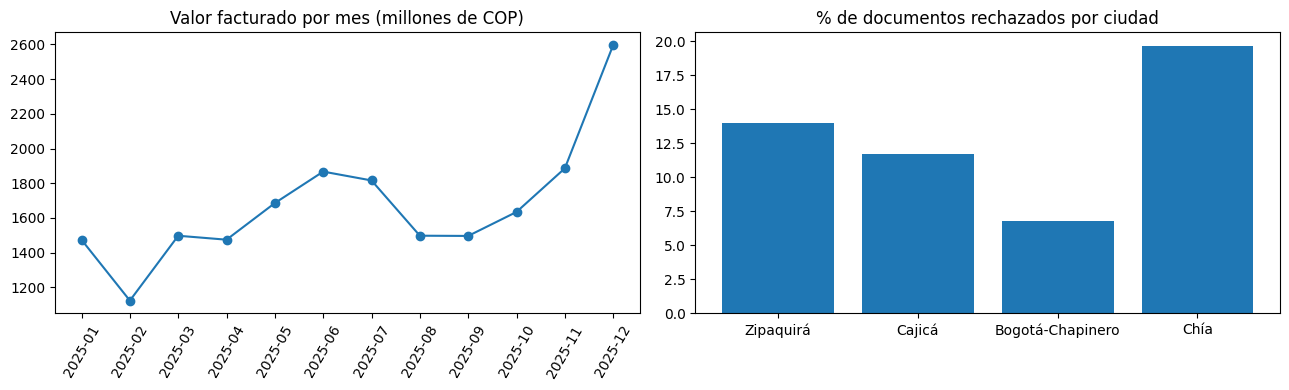

In [62]:
import matplotlib.pyplot as plt
mes = (df.withColumn("mes", F.date_format("fecha", "yyyy-MM")).groupBy("mes")
         .agg(F.sum("valor").alias("total")).orderBy("mes").toPandas())
tasa = (df.groupBy("ciudad")
          .agg((F.avg((F.col("estado_dian") == "Rechazada").cast("int")) * 100).alias("pct_rechazo"))
          .toPandas())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mes["mes"], mes["total"] / 1e6, marker="o")
ax[0].set_title("Valor facturado por mes (millones de COP)")
ax[0].tick_params(axis="x", rotation=60)
ax[1].bar(tasa["ciudad"], tasa["pct_rechazo"])
ax[1].set_title("% de documentos rechazados por ciudad")
plt.tight_layout()
plt.show()

**S-10. Plan de ejecución:** cómo Spark organiza internamente el trabajo.

In [63]:
df.groupBy("ciudad").count().explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[ciudad#19], functions=[count(1)])
   +- Exchange hashpartitioning(ciudad#19, 200), ENSURE_REQUIREMENTS, [plan_id=718]
      +- HashAggregate(keys=[ciudad#19], functions=[partial_count(1)])
         +- FileScan csv [ciudad#19] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[hdfs://localhost:9000/user/root/entrada/facturas.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<ciudad:string>




**S-11. Guardar un resultado de Spark en HDFS.**

In [64]:
res = df.groupBy("ciudad").count()
res.write.mode("overwrite").csv("hdfs://localhost:9000/user/root/spark_ciudad", header=True)
!hdfs dfs -ls /user/root/spark_ciudad

Found 2 items
-rw-r--r--   3 root supergroup          0 2026-11-07 16:41 /user/root/spark_ciudad/_SUCCESS
-rw-r--r--   3 root supergroup         80 2026-11-07 16:41 /user/root/spark_ciudad/part-00000-5b6f0c1c-3062-4cef-9bba-4119c6209931-c000.csv


## FASE 9. Comparación de tiempos: Hadoop MapReduce vs Spark
Misma tarea (facturas por ciudad) con tres métodos.

In [66]:
cont_mr, seg_mr = mr("mr_comparacion", "python3 /content/mapper.py 2", "python3 /content/reducer_suma.py",
                     combiner="python3 /content/reducer_suma.py")

t0 = time.time()
(sc.textFile(RUTA).filter(lambda l: not l.startswith("id_factura"))
   .map(lambda l: (l.split(",")[2], 1)).reduceByKey(lambda a, b: a + b).collect())
seg_rdd = time.time() - t0

t0 = time.time()
df.groupBy("ciudad").count().collect()
seg_df = time.time() - t0

pd.DataFrame({"Motor": ["Hadoop MapReduce (Streaming + combiner)", "Spark RDD", "Spark DataFrame"],
              "Segundos": [seg_mr, seg_rdd, seg_df]}).round(2)

COMANDO: hadoop jar hadoop-streaming-3.3.6.jar -D mapreduce.job.reduces=1 -input /user/root/entrada/facturas.csv -output /user/root/mr_comparacion -mapper python3 /content/mapper.py 2 -reducer python3 /content/reducer_suma.py -combiner python3 /content/reducer_suma.py
Tiempo total: 10.5 s
  Map input records: 53,269
  Map output records: 53,268
  Combine input records: 53,268
  Combine output records: 4
  Reduce input records: 16
  Reduce output records: 4


,Motor,Segundos
0,Hadoop MapReduce (Streaming + combiner),10.47
1,Spark RDD,1.24
2,Spark DataFrame,0.91
